# 01 · Data Understanding

Before building anything, I want to know what this dataset can and can't answer.
The goal of this notebook is simple: get familiar with each table, check coverage and data quality,
and confirm the data actually supports the questions in the README (baseline vs. incremental sales,
discount depth, and who should receive a promo).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# works whether the notebook runs from /notebooks or the project root
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

sorted(p.name for p in RAW.glob("*.csv"))

Matplotlib is building the font cache; this may take a moment.


['campaign_desc.csv',
 'campaign_table.csv',
 'causal_data.csv',
 'coupon.csv',
 'coupon_redempt.csv',
 'hh_demographic.csv',
 'product.csv',
 'transaction_data.csv']

## Load the tables

Everything except `causal_data` is small enough to load at once.
`causal_data` is ~660 MB, so I'll scan it in chunks later instead of loading it fully.
Column names are lower-cased so the rest of the code doesn't depend on how the file was exported.

In [2]:
def load(name):
    df = pd.read_csv(RAW / f"{name}.csv")
    df.columns = df.columns.str.lower()
    return df

transactions   = load("transaction_data")
products       = load("product")
demographics   = load("hh_demographic")
campaign_desc  = load("campaign_desc")
campaign_table = load("campaign_table")
coupons        = load("coupon")
coupon_redempt = load("coupon_redempt")

tables = {
    "transaction_data": transactions,
    "product": products,
    "hh_demographic": demographics,
    "campaign_desc": campaign_desc,
    "campaign_table": campaign_table,
    "coupon": coupons,
    "coupon_redempt": coupon_redempt,
}

pd.DataFrame(
    {name: {"rows": len(df), "columns": df.shape[1],
            "memory_MB": df.memory_usage(deep=True).sum() / 1e6}
     for name, df in tables.items()}
).T

,rows,columns,memory_MB
transaction_data,"2,595,732.00",12.00,249.19
product,"92,353.00",7.00,10.01
hh_demographic,801.00,8.00,0.09
campaign_desc,30.00,4.00,0.00
campaign_table,"7,208.00",3.00,0.21
coupon,"124,548.00",3.00,2.99
coupon_redempt,"2,318.00",4.00,0.07


In [3]:
for name, df in tables.items():
    print(f"── {name} ──")
    display(df.head(3))

── transaction_data ──


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.00,0.00
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.00,0.00
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.00,0.00


── product ──


,product_id,manufacturer,department,brand,commodity_desc,sub_commodity_desc,curr_size_of_product
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,


── hh_demographic ──


,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,household_key
0,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,1
1,45-54,A,50-74K,Homeowner,2 Adults No Kids,2,None/Unknown,7
2,25-34,U,25-34K,Unknown,2 Adults Kids,3,1,8


... (4 outputs left out)

── coupon ──


,coupon_upc,product_id,campaign
0,10000089061,27160,4
1,10000089064,27754,9
2,10000089073,28897,12


── coupon_redempt ──


,household_key,day,coupon_upc,campaign
0,1,421,10000085364,8
1,1,421,51700010076,8
2,1,427,54200000033,8


## How much does the data cover?

Time in this dataset is stored as `day` (1, 2, 3 …) and `week_no`, not real dates.
That's fine for modelling, but worth noting for the README.

In [4]:
t = transactions
coverage = pd.Series({
    "first day": t["day"].min(),
    "last day": t["day"].max(),
    "weeks": t["week_no"].nunique(),
    "households": t["household_key"].nunique(),
    "baskets": t["basket_id"].nunique(),
    "products sold": t["product_id"].nunique(),
    "stores": t["store_id"].nunique(),
    "total sales value": t["sales_value"].sum(),
})
coverage

first day                   1.00
last day                  711.00
weeks                     102.00
households              2,500.00
baskets               276,484.00
products sold          92,339.00
stores                    582.00
total sales value   8,057,463.08
dtype: float64

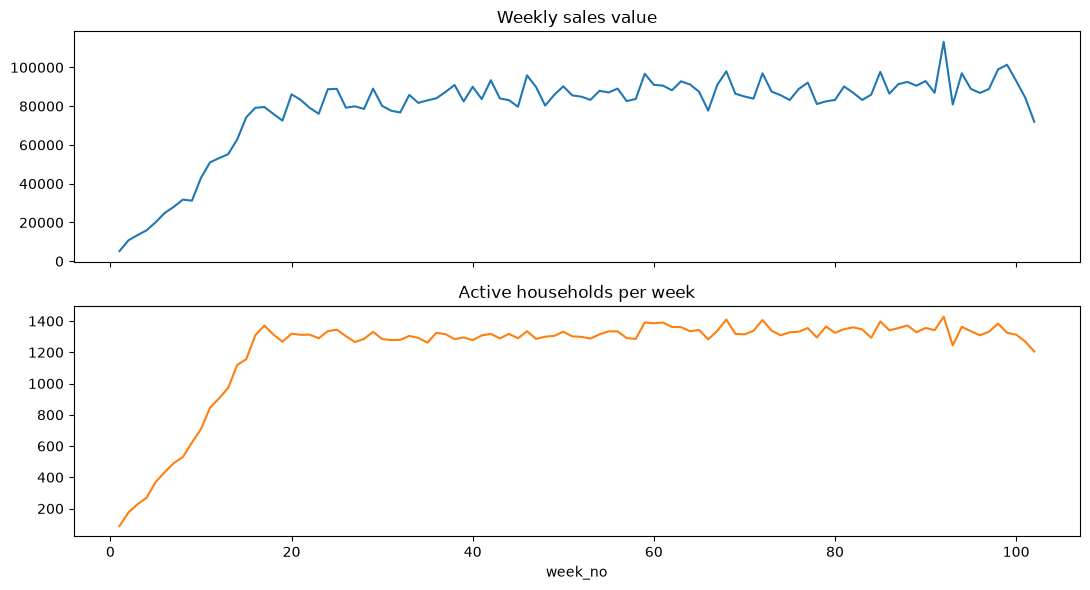

In [5]:
weekly = t.groupby("week_no").agg(
    sales=("sales_value", "sum"),
    households=("household_key", "nunique"),
)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
weekly["sales"].plot(ax=ax[0], title="Weekly sales value")
weekly["households"].plot(ax=ax[1], title="Active households per week", color="tab:orange")
ax[1].set_xlabel("week_no")
plt.tight_layout()
plt.savefig(FIGURES / "01_weekly_sales.png", dpi=150)
plt.show()

**Check:** the first and last few weeks are often incomplete. If they look much lower than the rest,
I should trim them before modelling the baseline.

## Discounts in the transactions

Two discount columns matter here (both are stored as negative numbers):

- `retail_disc` — the store's loyalty-card discount
- `coupon_disc` — discount from a coupon (`coupon_match_disc` is the store matching a manufacturer coupon)

`sales_value` is what the store received, so the list price is roughly `sales_value - retail_disc - coupon_disc`.

In [6]:
t = t.assign(
    has_retail_disc=t["retail_disc"] < 0,
    has_coupon_disc=t["coupon_disc"] < 0,
)
t["gross_value"] = t["sales_value"] - t["retail_disc"] - t["coupon_disc"]

summary = pd.Series({
    "% rows with retail discount": t["has_retail_disc"].mean() * 100,
    "% rows with coupon discount": t["has_coupon_disc"].mean() * 100,
    "% sales value with retail discount": t.loc[t["has_retail_disc"], "sales_value"].sum() / t["sales_value"].sum() * 100,
    "retail discount as % of gross": -t["retail_disc"].sum() / t["gross_value"].sum() * 100,
    "coupon discount as % of gross": -t["coupon_disc"].sum() / t["gross_value"].sum() * 100,
})
summary

% rows with retail discount          50.20
% rows with coupon discount           1.40
% sales value with retail discount   50.34
retail discount as % of gross        14.72
coupon discount as % of gross         0.45
dtype: float64

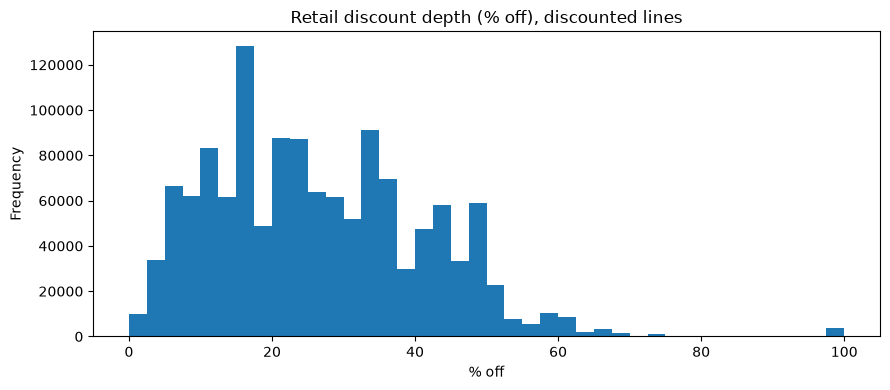

count   1,303,026.00
mean           26.53
std            14.97
min             0.00
10%             8.26
25%            15.50
50%            24.62
75%            37.11
90%            47.12
max           100.00
dtype: float64

In [7]:
# discount depth distribution for discounted lines only
disc = t.loc[t["has_retail_disc"] & (t["gross_value"] > 0)]
depth = (-disc["retail_disc"] / disc["gross_value"] * 100).clip(0, 100)

depth.plot.hist(bins=40, figsize=(9, 4), title="Retail discount depth (% off), discounted lines")
plt.xlabel("% off")
plt.tight_layout()
plt.savefig(FIGURES / "01_discount_depth.png", dpi=150)
plt.show()

depth.describe(percentiles=[.1, .25, .5, .75, .9])

## Campaigns

`campaign_table` tells me which household received which campaign. This is the table that makes
uplift modelling possible later, so I want to see how many households were targeted and how many weren't.

In [8]:
campaigns = (
    campaign_desc
    .assign(duration_days=lambda d: d["end_day"] - d["start_day"] + 1)
    .merge(
        campaign_table.groupby("campaign")["household_key"].nunique().rename("households_targeted"),
        on="campaign", how="left",
    )
    .merge(
        coupon_redempt.groupby("campaign").agg(
            redemptions=("coupon_upc", "size"),
            redeeming_households=("household_key", "nunique"),
        ),
        on="campaign", how="left",
    )
    .fillna({"redemptions": 0, "redeeming_households": 0})
)
campaigns["redemption_rate_%"] = campaigns["redeeming_households"] / campaigns["households_targeted"] * 100
campaigns.sort_values("start_day")

,description,campaign,start_day,end_day,duration_days,households_targeted,redemptions,redeeming_households,redemption_rate_%
29,TypeA,26,224,264,41,332,73,31,9.34
28,TypeC,27,237,300,64,12,1,1,8.33
27,TypeB,28,259,320,62,17,1,1,5.88
26,TypeB,29,281,334,54,118,24,13,11.02
25,TypeA,30,323,369,47,361,64,36,9.97
23,TypeB,1,346,383,38,13,1,1,7.69
24,TypeB,2,351,383,33,48,5,2,4.17
20,TypeC,3,356,412,57,12,2,2,16.67
22,TypeB,4,372,404,33,81,11,6,7.41
21,TypeB,5,377,411,35,166,13,8,4.82


In [9]:
all_hh = transactions["household_key"].nunique()
targeted_hh = campaign_table["household_key"].nunique()

pd.Series({
    "households in transactions": all_hh,
    "households ever targeted": targeted_hh,
    "households never targeted": all_hh - targeted_hh,
    "% never targeted": (all_hh - targeted_hh) / all_hh * 100,
    "campaigns by type": campaign_desc["description"].value_counts().to_dict(),
})

households in transactions                                     2500
households ever targeted                                       1584
households never targeted                                       916
% never targeted                                              36.64
campaigns by type             {'TypeB': 19, 'TypeC': 6, 'TypeA': 5}
dtype: object

**Why this matters:** uplift modelling needs a comparison group. If almost every household was targeted
by some campaign, I'll need to compare households *within* each campaign's time window instead
(targeted vs. not targeted for that specific campaign).

## In-store promotions (`causal_data`)

This table says whether a product was on display or in the weekly mailer, per store and week.
It's large, so I scan it in chunks and only keep summary counts.

In [10]:
display_counts = pd.Series(dtype="int64")
mailer_counts = pd.Series(dtype="int64")
weeks, rows = set(), 0

for chunk in pd.read_csv(RAW / "causal_data.csv", chunksize=2_000_000, dtype=str):
    chunk.columns = chunk.columns.str.lower()
    rows += len(chunk)
    weeks.update(chunk["week_no"].unique())
    display_counts = display_counts.add(chunk["display"].value_counts(), fill_value=0)
    mailer_counts = mailer_counts.add(chunk["mailer"].value_counts(), fill_value=0)

print(f"rows: {rows:,}   weeks covered: {len(weeks)}")
pd.concat(
    {"display": display_counts.astype(int), "mailer": mailer_counts.astype(int)}, axis=1
).fillna(0).astype(int)

rows: 36,786,524   weeks covered: 93


,display,mailer
0,21038745,11534183
1,1102141,0
2,1812840,0
3,2073738,0
4,592985,0
5,2575289,0
6,1816021,0
7,2362118,0
9,2699467,0
A,713180,17106789


In the dataset documentation, `0` means "not on display / not in mailer" and the other codes describe
the placement (e.g. front of store, end cap, front page of the mailer). Rows only exist for products
that had *some* promotion that week, so a missing row means no display or mailer.

## Data quality checks

In [11]:
quality = pd.DataFrame({
    name: {
        "missing values": int(df.isna().sum().sum()),
        "duplicate rows": int(df.duplicated().sum()),
    }
    for name, df in tables.items()
}).T
quality

,missing values,duplicate rows
transaction_data,0,0
product,0,0
hh_demographic,0,0
campaign_desc,0,0
campaign_table,0,0
coupon,0,5164
coupon_redempt,0,0


In [12]:
pd.Series({
    "quantity <= 0": int((transactions["quantity"] <= 0).sum()),
    "sales_value <= 0": int((transactions["sales_value"] <= 0).sum()),
    "sales_value < 0 (returns?)": int((transactions["sales_value"] < 0).sum()),
    "quantity > 100": int((transactions["quantity"] > 100).sum()),
    "max quantity": int(transactions["quantity"].max()),
})

quantity <= 0                 14466
sales_value <= 0              18850
sales_value < 0 (returns?)        0
quantity > 100                23136
max quantity                  89638
dtype: int64

In [13]:
# what are the huge-quantity lines? (often fuel or items sold by weight)
big = transactions.nlargest(10, "quantity").merge(products, on="product_id", how="left")
big[["product_id", "quantity", "sales_value", "department", "commodity_desc"]]

,product_id,quantity,sales_value,department,commodity_desc
0,6534178,89638,250.00,KIOSK-GAS,COUPON/MISC ITEMS
1,6544236,85055,210.00,MISC SALES TRAN,COUPON/MISC ITEMS
2,6534178,61335,150.21,KIOSK-GAS,COUPON/MISC ITEMS
3,6534178,51912,110.00,KIOSK-GAS,COUPON/MISC ITEMS
4,6534178,48073,121.10,KIOSK-GAS,COUPON/MISC ITEMS
5,6534178,45475,100.00,KIOSK-GAS,COUPON/MISC ITEMS
6,6534178,41833,115.00,KIOSK-GAS,COUPON/MISC ITEMS
7,6534178,41686,100.00,KIOSK-GAS,COUPON/MISC ITEMS
8,6544236,41485,85.00,MISC SALES TRAN,COUPON/MISC ITEMS
9,6534178,39365,72.00,KIOSK-GAS,COUPON/MISC ITEMS


In [14]:
pd.Series({
    "households with demographics": demographics["household_key"].nunique(),
    "% of all households": demographics["household_key"].nunique() / all_hh * 100,
    "products with no department": int(products["department"].isna().sum()),
})

households with demographics   801.00
% of all households             32.04
products with no department      0.00
dtype: float64

## What I noticed

_Fill this in after running the notebook. These notes feed straight into the README and the next notebook._

- Time coverage:
- Share of sales on discount:
- Typical discount depth:
- Campaigns and targeting:
- Data issues to fix in cleaning:
- Anything that changes the plan:

## Save a cleaner copy for the next notebook

In [15]:
PROCESSED.mkdir(parents=True, exist_ok=True)
transactions.to_parquet(PROCESSED / "transactions.parquet", index=False)
products.to_parquet(PROCESSED / "products.parquet", index=False)
print("saved to", PROCESSED)

saved to /Users/zemon/Desktop/promo-uplift-project/data/processed
